# Mobile game UA & monetization - analysis notebook
Independent case study, not affiliated with Rovio.

1. **A/B test** on the real, public Cookie Cats dataset (does moving the first gate from level 30 to 40 change retention?).
2. **LTV forecast and payback** by acquisition channel, on the simulated UA dataset (see `data/SOURCES.md`).

Every result is exported to `data/output/` and read by the Power BI report.

In [1]:
import numpy as np, pandas as pd
from scipy import stats
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = "../data/output/"

Matplotlib is building the font cache; this may take a moment.


## 1. A/B test - gate at level 30 vs 40 (real data)
Each player was randomly assigned to one version. We compare the share of players still playing 1 day and 7 days after install.

In [2]:
cc = pd.read_csv("../data/raw/players/cookie_cats.csv")
print(f"{len(cc):,} players")
summary = cc.groupby("version").agg(players=("userid", "size"),
                                    retention_1=("retention_1", "mean"),
                                    retention_7=("retention_7", "mean"))
summary

90,189 players


,players,retention_1,retention_7
version,,,
gate_30,44700,0.4482,0.1902
gate_40,45489,0.4423,0.1820


**Significance test.** A two-proportion z-test tells us whether the gap is larger than what random assignment alone would produce.
A bootstrap (resampling players 2,000 times) gives the same answer without any distribution assumption and shows how uncertain the gap is.

In [3]:
def ztest(col):
    a, b = cc[cc.version == "gate_30"][col], cc[cc.version == "gate_40"][col]
    p1, p2, n1, n2 = a.mean(), b.mean(), len(a), len(b)
    p = (a.sum() + b.sum()) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return p1, p2, p1 - p2, 2 * (1 - stats.norm.cdf(abs(z)))

rng = np.random.default_rng(7)
rows = []
for col, label in [("retention_1", "D1"), ("retention_7", "D7")]:
    p30, p40, diff, pval = ztest(col)
    boot = [cc.sample(frac=1, replace=True, random_state=int(s)).groupby("version")[col].mean()
            for s in rng.integers(0, 1e9, 2000)]
    boot = pd.DataFrame(boot)
    gap = boot["gate_30"] - boot["gate_40"]
    rows.append(dict(metric=label, gate_30=p30, gate_40=p40, difference_pts=diff * 100,
                     p_value=pval, ci_low_pts=np.percentile(gap, 2.5) * 100,
                     ci_high_pts=np.percentile(gap, 97.5) * 100,
                     prob_gate30_better=(gap > 0).mean()))
ab = pd.DataFrame(rows); ab.to_csv(OUT + "ab_test_results.csv", index=False); ab

,metric,gate_30,gate_40,difference_pts,p_value,ci_low_pts,ci_high_pts,prob_gate30_better
0,D1,0.4482,0.4423,0.5905,0.0744,-0.0898,1.2602,0.9550
1,D7,0.1902,0.1820,0.8201,0.0016,0.3082,1.3279,1.0000


**Reading.** Day-1 retention is almost identical. Day-7 retention is about 0.8 points higher with the gate at level 30,
the p-value is below 0.01 and the bootstrap gives gate 30 the advantage in practically every resample.
**Recommendation: keep the gate at level 30.** Moving it later lets players binge early and burn out sooner.

## 2. LTV forecast and payback by channel (simulated data)
`data/output/02_cumulative_arpi_by_channel.csv` (from SQL) gives revenue per install up to day 90 for cohorts old enough to be observed.
Cumulative revenue in casual games grows like a power curve: fast early, slower later. We fit `LTV(d) = a * (d + 1)^b` per channel on days 0-90,
check the fit, then extrapolate to day 180 and day 365.

In [4]:
arpi = pd.read_csv(OUT + "02_cumulative_arpi_by_channel.csv")
roas = pd.read_csv(OUT + "03_channel_roas.csv").set_index("channel")
f = lambda d, a, b: a * (d + 1) ** b

fits, curves = [], []
for ch, g in arpi.groupby("channel"):
    (a, b), _ = curve_fit(f, g.day_n, g.cumulative_arpi_eur, p0=(0.1, 0.5))
    pred = f(g.day_n, a, b)
    mape = (abs(pred - g.cumulative_arpi_eur) / g.cumulative_arpi_eur).mean()
    # hold-out check: fit on days 0-30 only, predict day 90
    g30 = g[g.day_n <= 30]
    (a30, b30), _ = curve_fit(f, g30.day_n, g30.cumulative_arpi_eur, p0=(0.1, 0.5))
    actual90 = g.loc[g.day_n == 90, "cumulative_arpi_eur"].iloc[0]
    holdout_err = f(90, a30, b30) / actual90 - 1
    cpi = roas.cpi_eur.get(ch, 0.0)
    payback = next((d for d in range(0, 1001) if cpi and f(d, a, b) >= cpi), None)
    fits.append(dict(channel=ch, a=a, b=b, fit_mape=mape, holdout_d30_to_d90_error=holdout_err,
                     ltv_d90_actual=actual90, ltv_d180_forecast=f(180, a, b), ltv_d365_forecast=f(365, a, b),
                     cpi_eur=cpi, roas_d365_forecast=(f(365, a, b) / cpi) if cpi else None,
                     payback_day=payback))
    for d in range(0, 366):
        curves.append(dict(channel=ch, day_n=d, ltv_forecast_eur=f(d, a, b),
                           ltv_actual_eur=g.set_index("day_n").cumulative_arpi_eur.get(d)))
fits = pd.DataFrame(fits).sort_values("roas_d365_forecast", ascending=False)
pd.DataFrame(curves).to_csv(OUT + "ltv_curves.csv", index=False)
fits.to_csv(OUT + "ltv_forecast_by_channel.csv", index=False)
fits[["channel", "cpi_eur", "ltv_d90_actual", "ltv_d180_forecast", "ltv_d365_forecast",
      "roas_d365_forecast", "payback_day", "fit_mape", "holdout_d30_to_d90_error"]]

,channel,cpi_eur,ltv_d90_actual,ltv_d180_forecast,ltv_d365_forecast,roas_d365_forecast,payback_day,fit_mape,holdout_d30_to_d90_error
0,AppLovin,3.6000,1.6947,2.5980,4.0184,1.1162,306.0000,0.0741,0.0303
1,Google,2.5900,1.2335,1.7986,2.6350,1.0174,354.0000,0.0509,0.0552
2,Meta,3.0000,1.2162,1.8258,2.7653,0.9218,420.0000,0.0740,0.0501
5,Unity Ads,2.1800,0.8560,1.2340,1.7920,0.8220,529.0000,0.0393,0.0442
4,TikTok,1.7000,0.4538,0.6454,0.9302,0.5472,NaN,0.0505,-0.0098
3,Organic,0.0000,1.5548,2.3830,3.6938,NaN,NaN,0.0336,0.0002


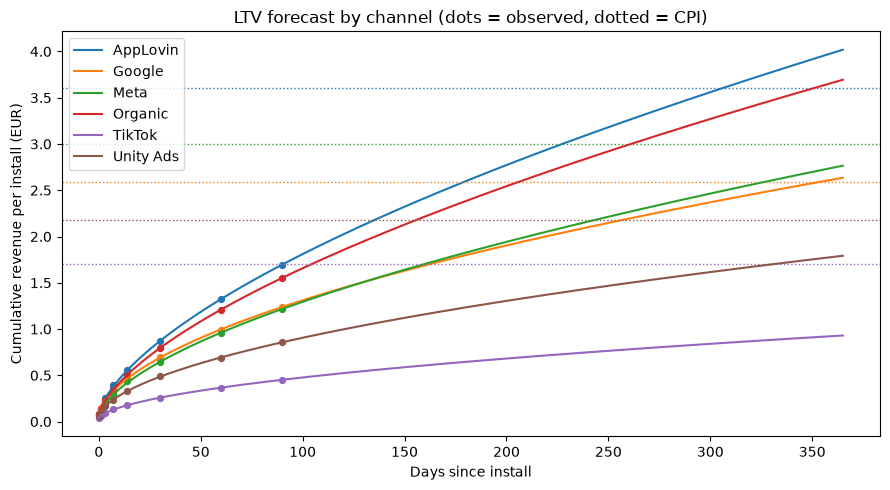

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
cv = pd.DataFrame(curves)
for ch, g in cv.groupby("channel"):
    line, = ax.plot(g.day_n, g.ltv_forecast_eur, label=ch)
    obs = g.dropna(subset=["ltv_actual_eur"])
    ax.scatter(obs.day_n, obs.ltv_actual_eur, color=line.get_color(), s=18)
    if ch in roas.index:
        ax.axhline(roas.cpi_eur[ch], color=line.get_color(), ls=":", lw=1)
ax.set(xlabel="Days since install", ylabel="Cumulative revenue per install (EUR)",
       title="LTV forecast by channel (dots = observed, dotted = CPI)")
ax.legend(); plt.tight_layout(); plt.savefig("../docs/ltv_forecast.png", dpi=150)

**Reading.**
- The power curve fits the observed points closely, and a fit on days 0-30 alone predicts day 90 within a few percent: the forecast is usable for early decisions.
- **AppLovin** has the highest CPI but also the best payers, and it pays back first.
- **TikTok** is the cheapest channel but its players retain and pay least: it does not pay back within a year at current CPI.
- Decision: shift budget from TikTok and Meta toward AppLovin and Google, and set a CPI ceiling per channel equal to its forecast D365 LTV.